In [1]:
import pandas as pd
import numpy as np

In [2]:
courses = pd.read_csv('../datasets/courses.csv')
students = pd.read_csv('../datasets/students.csv')
nov = pd.read_csv('../datasets/reg-month1.csv')
dec = pd.read_csv('../datasets/reg-month2.csv')

matches = pd.read_csv('../datasets/matches.csv')
delivery = pd.read_csv('../datasets/deliveries.csv')

In [10]:
dec.head()

,student_id,course_id
0,3,5
1,16,7
2,12,10
3,12,1
4,14,9


In [6]:
nov.head()

,student_id,course_id
0,23,1
1,15,5
2,18,6
3,23,4
4,16,9


In [8]:
students.head()

,student_id,name,partner
0,1,Kailash Harjo,23
1,2,Esha Butala,1
2,3,Parveen Bhalla,3
3,4,Marlo Dugal,14
4,5,Kusum Bahri,6


In [ ]:
# pd.concat
# ignore_index
# df.append -> This is not in pandas new versions
# mullitindex -> fetch using iloc
# concat dataframes horizontally

In [16]:
regs = pd.concat([nov, dec], ignore_index=True)
regs

,student_id,course_id
0,23,1
1,15,5
2,18,6
3,23,4
4,16,9
5,18,1
6,1,1
7,7,8
8,22,3
9,15,1


In [31]:
multi = pd.concat([nov, dec], keys=['Nov', 'Dec']) # Multiindex Dataframe
multi.loc['Nov']
multi.loc['Dec']
multi.loc['Nov', 0]
multi.loc['Dec', 4]

student_id    14
course_id      9
Name: (Dec, 4), dtype: int64

In [33]:
# inner join
pd.concat([nov, dec], axis=1)

,student_id,course_id,student_id,course_id
0,23.0,1.0,3,5
1,15.0,5.0,16,7
2,18.0,6.0,12,10
3,23.0,4.0,12,1
4,16.0,9.0,14,9
5,18.0,1.0,7,7
6,1.0,1.0,7,2
7,7.0,8.0,16,3
8,22.0,3.0,17,10
9,15.0,1.0,11,8


In [34]:
# inner join
students.merge(regs, how='inner', on='student_id')

,student_id,name,partner,course_id
0,1,Kailash Harjo,23,1
1,1,Kailash Harjo,23,6
2,1,Kailash Harjo,23,10
3,1,Kailash Harjo,23,9
4,2,Esha Butala,1,5
5,3,Parveen Bhalla,3,3
6,3,Parveen Bhalla,3,5
7,7,Tarun Thaker,9,8
8,7,Tarun Thaker,9,10
9,7,Tarun Thaker,9,7


In [ ]:
# left join
courses.merge(regs, how='left', on='course_id')

,course_id,course_name,price,student_id
0,1,python,2499,23.0
1,1,python,2499,18.0
2,1,python,2499,1.0
3,1,python,2499,15.0
4,1,python,2499,21.0
5,1,python,2499,25.0
6,1,python,2499,12.0
7,1,python,2499,14.0
8,1,python,2499,38.0
9,2,sql,3499,19.0


In [42]:
# right join
temp_df = pd.DataFrame({
    'student_id': [26, 27, 28],
    'name': ['Nitish', 'Ankit', 'Rahul'],
    'partner': [28, 26, 17]
})

students = pd.concat([students, temp_df], ignore_index=True)
students.tail()
students.merge(regs, how='right', on='student_id')

,student_id,name,partner,course_id
0,23,Chhavi Lachman,18.0,1
1,15,Preet Sha,16.0,5
2,18,Fardeen Mahabir,13.0,6
3,23,Chhavi Lachman,18.0,4
4,16,Elias Dodiya,25.0,9
5,18,Fardeen Mahabir,13.0,1
6,1,Kailash Harjo,23.0,1
7,7,Tarun Thaker,9.0,8
8,22,Yash Sethi,21.0,3
9,15,Preet Sha,16.0,1


In [43]:
regs.merge(students, how='left', on='student_id')

,student_id,course_id,name,partner
0,23,1,Chhavi Lachman,18.0
1,15,5,Preet Sha,16.0
2,18,6,Fardeen Mahabir,13.0
3,23,4,Chhavi Lachman,18.0
4,16,9,Elias Dodiya,25.0
5,18,1,Fardeen Mahabir,13.0
6,1,1,Kailash Harjo,23.0
7,7,8,Tarun Thaker,9.0
8,22,3,Yash Sethi,21.0
9,15,1,Preet Sha,16.0


In [46]:
# outer join
students.merge(regs, how='outer', on='student_id').tail(10)

,student_id,name,partner,course_id
65,27,Ankit,26.0,NaN
66,27,Ankit,26.0,NaN
67,28,Rahul,17.0,NaN
68,28,Rahul,17.0,NaN
69,28,Rahul,17.0,NaN
70,28,Rahul,17.0,NaN
71,28,Rahul,17.0,NaN
72,38,NaN,NaN,1.0
73,42,NaN,NaN,9.0
74,50,NaN,NaN,8.0


In [51]:
# 1. find total revenue generated
total = regs.merge(courses, how='inner', on='course_id')['price'].sum()
print(total)

154247


In [58]:
# 2. find month by month revenue
temp_df = pd.concat([nov, dec], keys=['Nov', 'Dec']).reset_index()
temp_df.merge(courses, on="course_id").groupby(['level_0'])['price'].sum()

level_0
Dec    65072
Nov    89175
Name: price, dtype: int64

In [64]:
# 3. Print the registration table
# cols -> name -> course -> price
regs.merge(students, on='student_id').merge(courses, on='course_id')[['name', 'course_name', 'price']]

,name,course_name,price
0,Chhavi Lachman,python,2499
1,Preet Sha,tableau,2499
2,Fardeen Mahabir,power bi,1899
3,Chhavi Lachman,machine learning,9999
4,Elias Dodiya,plotly,699
5,Fardeen Mahabir,python,2499
6,Kailash Harjo,python,2499
7,Tarun Thaker,pandas,1099
8,Yash Sethi,data analysis,4999
9,Preet Sha,python,2499


<Axes: xlabel='course_name'>

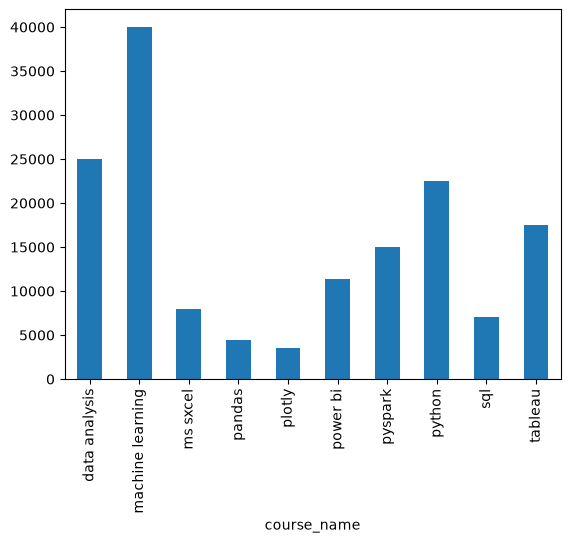

In [69]:
# 4. Plot bar chart for revenue/course
regs.merge(courses, on='course_id').groupby(['course_name'])['price'].sum().plot(kind='bar')

In [75]:
# 5. find students who enrolled in both the months
common_student_id = np.intersect1d(nov['student_id'], dec['student_id'])
students[students['student_id'].isin(common_student_id)]

,student_id,name,partner
0,1,Kailash Harjo,23
2,3,Parveen Bhalla,3
6,7,Tarun Thaker,9
10,11,David Mukhopadhyay,20
15,16,Elias Dodiya,25
16,17,Yasmin Palan,7
17,18,Fardeen Mahabir,13
21,22,Yash Sethi,21
22,23,Chhavi Lachman,18


In [77]:
# 6. find course that got no enrollment
courses['course_id']
regs['course_id']

course_id_list = np.setdiff1d(courses['course_id'], regs['course_id'])
courses[courses['course_id'].isin(course_id_list)]

,course_id,course_name,price
10,11,Numpy,699
11,12,C++,1299


In [ ]:
# 7. find students who did not enroll into any courses
student_id_list = np.setdiff1d(students['student_id'], regs['student_id'])
students[students['student_id'].isin(student_id_list)]

(22, 3)

In [82]:
# 8. Print student name -> partner name for all enrolled students
# self join
students.merge(students, how='inner', left_on='partner', right_on='student_id')[['name_x', 'name_y']]

,name_x,name_y
0,Kailash Harjo,Chhavi Lachman
1,Esha Butala,Kailash Harjo
2,Parveen Bhalla,Parveen Bhalla
3,Marlo Dugal,Pranab Natarajan
4,Kusum Bahri,Lakshmi Contractor
...,...,...
75,Ankit,Nitish
76,Ankit,Nitish
77,Ankit,Nitish
78,Ankit,Nitish


In [88]:
# 9. find top 3 students who did most number enrollments
regs.merge(students, on='student_id').groupby(['student_id', 'name'])['name'].count().sort_values(ascending=False).head(3)

student_id  name            
23          Chhavi Lachman      6
7           Tarun Thaker        5
14          Pranab Natarajan    4
Name: name, dtype: int64

In [89]:
# 10. find top 3 students who spent most amount of money on courses
regs.merge(students, on='student_id').merge(courses, on='course_id').groupby(['student_id', 'name'])['price'].sum().sort_values(ascending=False).head(3)

student_id  name            
23          Chhavi Lachman      22594
14          Pranab Natarajan    15096
19          Qabeel Raman        13498
Name: price, dtype: int64

In [91]:
# Alternate syntax for merge

pd.merge(students, regs, how='inner', on='student_id').head()

,student_id,name,partner,course_id
0,1,Kailash Harjo,23,1
1,1,Kailash Harjo,23,6
2,1,Kailash Harjo,23,10
3,1,Kailash Harjo,23,9
4,2,Esha Butala,1,5


In [ ]:
# IPL Problems

In [93]:
matches.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


In [94]:
delivery.head()

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN
3,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
4,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,NaN,NaN,NaN


In [109]:
# find top 3 studiums with highest sixes/match ratio
temp_df = delivery.merge(matches, left_on='match_id', right_on='id')
six_df = temp_df[temp_df['batsman_runs'] == 6]

# stadium -> sixes
num_sixes = six_df.groupby('venue')['venue'].count()

# stadium -> matches
num_matches = matches['venue'].value_counts()

(num_sixes/num_matches).sort_values(ascending=False).head()

venue
Holkar Cricket Stadium                                 17.600000
M Chinnaswamy Stadium                                  13.227273
Sharjah Cricket Stadium                                12.666667
Himachal Pradesh Cricket Association Stadium           12.000000
Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium    11.727273
dtype: float64

In [116]:
# find orange cap holder of all the seasons
temp_df.groupby(['season', 'batsman'])['batsman_runs'].sum().reset_index().sort_values('batsman_runs', ascending=False).drop_duplicates(subset=['season'], keep='first').sort_values('season')

,season,batsman,batsman_runs
115,2008,SE Marsh,616
229,2009,ML Hayden,572
446,2010,SR Tendulkar,618
502,2011,CH Gayle,608
684,2012,CH Gayle,733
910,2013,MEK Hussey,733
1088,2014,RV Uthappa,660
1148,2015,DA Warner,562
1383,2016,V Kohli,973
1422,2017,DA Warner,641
